In [1]:
import torch
from torch import nn, optim


class LinearRegressionModel(nn.Module):
    """
    선형 회귀 모델 정의
    """
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(1, 1)  # 입력 차원 1, 출력 차원 1

    def forward(self, x):
        return self.linear(x)


# 모델, 손실 함수 및 옵티마이저 초기화
model = LinearRegressionModel()
criterion = nn.MSELoss()  # 평균 제곱 오차 손실
optimizer = optim.SGD(model.parameters(), lr=0.01)  # 확률적 경사 하강법

# 임의 데이터 생성
x_train = torch.randn(100, 1)  # 훈련 데이터 100개
y_train = x_train * 2 + 3 + torch.randn(100, 1) * 0.1  # y = 2x + 3에 노이즈 추가

num_epochs = 100
# 반복하면서 훈련
for epoch in range(num_epochs):
    predictions = model(x_train)  # Forwardpass: 입력을 모델에 전달하여 예측값 계산

    loss = criterion(predictions, y_train)  # 손실 계산

    optimizer.zero_grad()  # 초기화
    loss.backward()  # 역전파
    optimizer.step()

    if (epoch + 1) % 10 == 0:
        print(f"Epoch: [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}")


print("finished training")

Epoch: [10/100], Loss: 4.9162
Epoch: [20/100], Loss: 3.4294
Epoch: [30/100], Loss: 2.3991
Epoch: [40/100], Loss: 1.6833
Epoch: [50/100], Loss: 1.1849
Epoch: [60/100], Loss: 0.8368
Epoch: [70/100], Loss: 0.5932
Epoch: [80/100], Loss: 0.4222
Epoch: [90/100], Loss: 0.3019
Epoch: [100/100], Loss: 0.2170
finished training


In [29]:
import torch

print(torch.__version__)


# https://pytorch.org/get-started/locally/#start-locally
print("CUDA available:", torch.cuda.is_available())
print("PyTorch CUDA build:", torch.version.cuda)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device: ", device)

# A simple model: 4 input features -> 2 output values
model = nn.Linear(4, 2).to(device)
# One batch of 8 examples, each with 4 features
inputs = torch.randn(8, 4).to(device)
outputs = model(inputs)
print(outputs.shape)  # torch.Size([8, 2])
print(outputs.device) # cuda:0 if CUDA is available, otherwise cpu

tensor = torch.ones(4, 4)

print(tensor)
tensor[:, 1] = 0
tensor[:, 3] = 0
print(tensor)


2.14.1+cu132
CUDA available: True
PyTorch CUDA build: 13.2
device:  cuda
torch.Size([8, 2])
cuda:0
tensor([[1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.],
        [1., 1., 1., 1.]])
tensor([[1., 0., 1., 0.],
        [1., 0., 1., 0.],
        [1., 0., 1., 0.],
        [1., 0., 1., 0.]])


Using cuda device
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


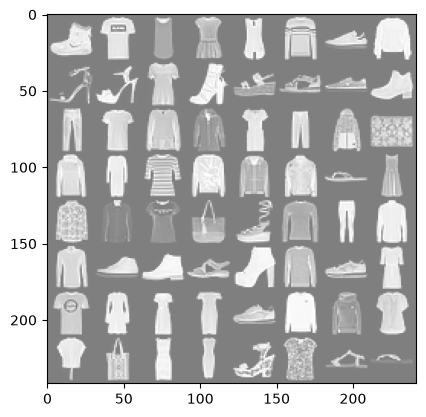

Ankle boot T-shirt/top T-shirt/top Dress T-shirt/top Pullover Sneaker Pullover Sandal Sandal T-shirt/top Ankle boot Sandal Sandal Sneaker Ankle boot Trouser T-shirt/top Shirt Coat  Dress Trouser Coat  Bag   Coat  Dress T-shirt/top Pullover Coat  Coat  Sandal Dress Shirt Shirt T-shirt/top Bag   Sandal Pullover Trouser Shirt Shirt Sneaker Ankle boot Sandal Ankle boot Pullover Sneaker Dress T-shirt/top Dress Dress Dress Sneaker Pullover Pullover Shirt Shirt Bag   Dress Dress Sandal T-shirt/top Sandal Sandal
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)
Epoch 1
------------------------
loss: 2.294181  [    0/60000]
loss: 2.286527  [ 6400/60000]
loss: 2.273741  [12800/60000]
loss: 2.279068  [19200/60000]
loss: 2.253429  [2

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import ToTensor

# Get cpu or gpu device for training.
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

# training data
training_data = datasets.FashionMNIST(
    root="data",
    train=True,  # 훈련용
    download=True,
    transform=ToTensor()
)

# test data
test_data = datasets.FashionMNIST(
    root="data",
    train=False,  # 테스트용
    download=True,
    transform=ToTensor()
)


# Create data loaders.
batch_size = 64

train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break


# functions to show an image

def imshow(img):
    img = img / 2 + 0.5  # 비정규화 unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# get some random training images
dataiter = iter(train_dataloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))

# print labels
classes = (
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
)
print(" ".join(f"{classes[labels[j]]:5s}" for j in range(batch_size)))


class NeuralNetwork(nn.Module):
    """Define model"""
    def __init__(self):
        super().__init__()

        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28*28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


model = NeuralNetwork().to(device)
print(model)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3)


def train(dataloader, model, loss_fn, optimizer):
    """학습코드"""
    size = len(dataloader.dataset)
    model.train()  # 훈련
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        optimizer.zero_grad()  # 초기화
        loss.backward()  # 역전파
        optimizer.step()

        if batch % 100 == 0:
            loss, current = loss.item(), batch  * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

def test(dataloader, model, loss_fn):
    """테스트 코드"""
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()  # 평가
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)

            # Compute prediction error
            pred = model(X)
            test_loss += loss_fn(pred, y).item()

            correct += (pred.argmax(1) == y).type(torch.float).sum().item()

    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100 * correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")


# 학습 실행
epochs = 2
for t in range(epochs):
    print(f"Epoch {t+1}\n------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)


print("Done!")

print(device)

inference

cuda


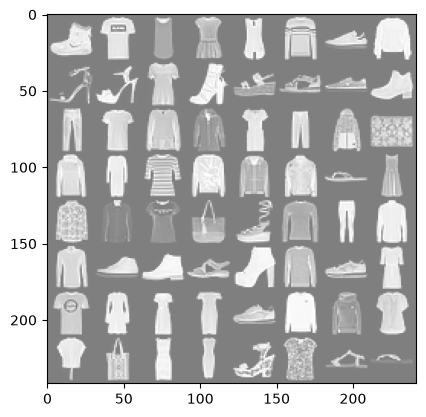

Ankle boot T-shirt/top T-shirt/top Dress T-shirt/top Pullover Sneaker Pullover Sandal Sandal T-shirt/top Ankle boot Sandal Sandal Sneaker Ankle boot Trouser T-shirt/top Shirt Coat  Dress Trouser Coat  Bag   Coat  Dress T-shirt/top Pullover Coat  Coat  Sandal Dress Shirt Shirt T-shirt/top Bag   Sandal Pullover Trouser Shirt Shirt Sneaker Ankle boot Sandal Ankle boot Pullover Sneaker Dress T-shirt/top Dress Dress Dress Sneaker Pullover Pullover Shirt Shirt Bag   Dress Dress Sandal T-shirt/top Sandal Sandal


In [14]:
print(device)

# get some random training images
dataiter = iter(train_dataloader)
images, labels = next(dataiter)

# show images
imshow(torchvision.utils.make_grid(images))

# print labels
classes = (
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
)
print(" ".join(f"{classes[labels[j]]:5s}" for j in range(batch_size)))


In [ ]:
# device = "cuda" if torch.cuda.is_available() else "cpu"
# model = NeuralNetwork().to(device)
print(device)

model.eval()  # 평가
# x, y = test_data[0][0], test_data[0][1]  # RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_addmm)

x, y = test_data[0]
x = x.unsqueeze(0).to(device)

with torch.no_grad():
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]

    print(f'Predicted: "{predicted}", Actual: "{actual}" ')


cuda
Predicted: "Ankle boot", Actual: "Ankle boot" 


In [19]:
print(device)

model.eval()  # 평가
# RuntimeError: Expected all tensors to be on the same device, but got mat1 is on cpu, different from other tensors on cuda:0 (when checking argument in method wrapper_CUDA_addmm)
# x, y = test_data[1][0], test_data[1][1]

x, y = test_data[1]
x = x.unsqueeze(0).to(device)

with torch.no_grad():
    pred = model(x)
    predicted, actual = classes[pred[0].argmax(0)], classes[y]

    print(f'Predicted: "{predicted}", Actual: "{actual}" ')


cuda
Predicted: "Coat", Actual: "Pullover" 
